# Entrenamiento integrador: de los datos crudos a la predicción

**TP Integrador de Aprendizaje Automático — Entrega 5**

Este notebook recorre el trabajo completo en orden y en un solo archivo: descarga, preparación, baselines, regresión, clasificación, integración de los dos sistemas y verificación de lo que se publica en la aplicación.

Sirve para dos cosas:

- comprobar que todas las etapas se pueden volver a ejecutar desde cero y producen las mismas tablas y los mismos modelos;
- reunir en un solo lugar las decisiones que se tomaron en las entregas anteriores.

Los notebooks `02_preparacion_y_baselines.ipynb`, `03_regresion.ipynb` y `04_clasificacion.ipynb` conservan el desarrollo y las figuras de cada entrega. Este es el recorrido de conjunto.

## Cómo ejecutarlo

```bash
python -m venv .venv
.venv\Scripts\activate
pip install -r requirements-dev.txt
python -m jupyter nbconvert --to notebook --execute --inplace notebooks/entrenamiento.ipynb
```

Tiempo aproximado: entre 3 y 5 minutos en una computadora común. El archivo de rendimientos y los datos diarios de clima se reutilizan si ya están en disco. Si la caché de clima está vacía, la descarga desde NASA POWER tarda alrededor de veinte minutos, porque consulta un partido por vez.

## 0. Entorno

Se agrega la raíz del repositorio al `sys.path` para poder importar el paquete `src` y se imprimen las versiones, para que quede registrado con qué entorno se generaron las tablas y los modelos.

In [1]:
from pathlib import Path
import json
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

import joblib
import sklearn

from src.config import (
    CLIMA_COLS,
    COST_FN,
    COST_FP,
    CROPS,
    DATASET_MODELADO,
    DATASET_MODELADO_CLIMA,
    FIGURAS_DIR,
    MODEL_LABELS,
    MODELOS_DIR,
    RANDOM_STATE,
    RATIO_EXTREMO,
    TEST_START,
    THRESHOLD,
    TRAIN_END,
    VALIDATION_END,
)
from src.descargar_datos import download, sha256
from src.preparar_datos import (
    build_datasets,
    class_summaries,
    clean_raw,
    extreme_ratio_cases,
    read_raw,
)
from src.baselines import run_baselines

# src.baselines fija el backend Agg para poder correr por consola. En el
# notebook se vuelve a inline para que las figuras se vean.
%matplotlib inline

plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e4e3df",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
    }
)
FIGURAS_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("Repositorio:", ROOT.name)

Python: 3.14.2
pandas: 3.0.2
numpy: 2.4.2
scikit-learn: 1.9.0
joblib: 1.5.3
Repositorio: proyecto


## 1. El problema y las decisiones que lo enmarcan

La unidad de análisis es **partido × cultivo × campaña**. La variable que se predice es el **ratio**: el rendimiento de la campaña dividido por el promedio de las cinco campañas anteriores del mismo partido y cultivo. Se modela el ratio y no los kilos por hectárea porque así se descuenta la tendencia tecnológica y la diferencia de suelos entre partidos, que un modelo entrenado hasta 2013 no puede extrapolar.

La campaña es **mala** cuando el ratio real es menor a 0,85, es decir, cuando la cosecha cae más del 15 % respecto del promedio reciente. El costo de un falso negativo se fija en el doble del de un falso positivo: no avisar de una campaña mala cuesta más que una revisión innecesaria.

In [2]:
decisiones = pd.DataFrame(
    [
        ("Unidad de análisis", "partido × cultivo × campaña"),
        ("Cultivos", ", ".join(CROPS)),
        ("Objetivo de la regresión", "ratio = rendimiento / promedio de las 5 campañas anteriores"),
        ("Clase positiva", f"ratio real < {THRESHOLD} (caída mayor al 15 %)"),
        ("Costo de un falso negativo", f"{COST_FN:.0f}"),
        ("Costo de un falso positivo", f"{COST_FP:.0f}"),
        ("Umbral teórico de probabilidad", f"{COST_FP / (COST_FP + COST_FN):.2f}"),
        ("Train", f"1981/82 a {TRAIN_END}/{str(TRAIN_END + 1)[-2:]}"),
        ("Validación", f"{TRAIN_END + 1}/{str(TRAIN_END + 2)[-2:]} a {VALIDATION_END}/{str(VALIDATION_END + 1)[-2:]}"),
        ("Test", f"{TEST_START}/{str(TEST_START + 1)[-2:]} a 2024/25"),
        ("Semilla", str(RANDOM_STATE)),
    ],
    columns=["decisión", "valor"],
)
display(decisiones)

,decisión,valor
0,Unidad de análisis,partido × cultivo × campaña
1,Cultivos,"Maíz, Trigo total, Girasol, Soja total"
2,Objetivo de la regresión,ratio = rendimiento / promedio de las 5 campañ...
3,Clase positiva,ratio real < 0.85 (caída mayor al 15 %)
4,Costo de un falso negativo,2
5,Costo de un falso positivo,1
6,Umbral teórico de probabilidad,0.33
7,Train,1981/82 a 2013/14
8,Validación,2014/15 a 2018/19
9,Test,2019/20 a 2024/25


## 2. Datos de rendimiento

La fuente es el catálogo de datos abiertos de la Provincia de Buenos Aires: estimaciones agrícolas por partido y campaña, con licencia CC BY 4.0. La descarga es idempotente: si el archivo ya está en `datos/raw/`, se reutiliza y se verifica su hash.

In [3]:
raw_path = download(verbose=False)
print("Archivo:", raw_path.relative_to(ROOT).as_posix())
print("Tamaño:", round(raw_path.stat().st_size / 1_048_576, 2), "MB")
print("sha256:", sha256(raw_path))

meta_raw = json.loads((raw_path.parent / "metadata.json").read_text(encoding="utf-8"))
for clave in ["fuente", "licencia", "filas", "descargado_utc"]:
    print(f"{clave}: {meta_raw[clave]}")

Archivo: datos/raw/estimaciones-agricolas-1969_2026.csv
Tamaño: 2.82 MB
sha256: a3b8e1295978343847324b2c3dff4d41b985f093372b34b1290cbc7ad75934e0
fuente: https://catalogo.datos.gba.gob.ar/dataset/estimaciones-agro
licencia: CC BY 4.0
filas: 53905
descargado_utc: 2026-10-28T16:26:39+00:00


Cada fila del archivo original es un partido, un cultivo y una campaña, con superficie sembrada, superficie cosechada y producción. De ahí sale el rendimiento en kg/ha.

In [4]:
raw = read_raw()
print("Filas:", len(raw))
print("Columnas:", len(raw.columns))
display(raw.head(3))

Filas: 53905
Columnas: 8


,cultivo,campania,municipio_id,municipio_nombre,superficie_sembrada,superficie_cosechada,produccion,rendimiento
0,Ajo,1969/70,6854,25 De Mayo,3,3,10,3333
1,Ajo,1970/71,6854,25 De Mayo,1,1,3,3000
2,Ajo,1969/70,6014,Adolfo Gonzales Chaves,15,15,82,5467


### 2.1 Limpieza

Se conservan cuatro cultivos: maíz, trigo total, girasol y soja total. Se excluyen sorgo, por la alta proporción de rendimientos en cero, y cebada cervecera, por la serie corta. También se excluye la campaña 2025/26, que está incompleta. Cada criterio queda registrado con la cantidad de filas que descarta.

In [5]:
limpio_base, registro = clean_raw(raw)
display(registro)
print("Filas limpias:", len(limpio_base))

,paso,filas_antes,filas_despues,filas_removidas,motivo
0,lectura_csv,53905,53905,0,Archivo original
1,filtrar_cultivos,53905,20495,33410,"Cultivos del alcance: Maíz, Trigo total, Giras..."
2,filtrar_campanias,20495,20393,102,Se conservan campañas 1969 a 2024; se excluye ...
3,quitar_municipio_ignorado,20393,20393,0,Municipio 'Ignorado' sin partido asignado
4,quitar_rendimiento_invalido,20393,20392,1,Rendimiento nulo o negativo
5,quitar_superficie_invalida,20392,20390,2,Superficie sembrada nula o no positiva
6,quitar_duplicados,20390,20390,0,"Duplicados por cultivo, campaña y municipio"
7,ordenar,20390,20390,0,"Orden por cultivo, municipio y campaña"


Filas limpias: 20390


### 2.2 Promedio de cinco campañas y objetivos

El promedio se calcula sobre una grilla de calendario: para cada cultivo y partido se usan las cinco campañas inmediatamente anteriores. Si falta un año, el promedio queda nulo y la fila no entra al modelado: así se respeta el momento en que se toma la decisión y no se saltean huecos. La cantidad de ceros en esas cinco campañas se guarda en `prev5_ceros`, porque explica los ratios extremos.

El split es temporal y se fija acá, antes de cualquier búsqueda: train hasta 2012/13, validación 2013/14 a 2018/19 y test desde 2019/20. El test no se usa para elegir modelos ni hiperparámetros.

In [6]:
limpio, modelado = build_datasets(limpio_base)
print("Filas limpias:", len(limpio))
print("Filas modeladas:", len(modelado))
print("Perdidas al construir prev5 y objetivos:", len(limpio) - len(modelado))

por_cultivo, por_campania = class_summaries(modelado)
display(por_cultivo.round(3))
display(por_campania.tail(8).round(3))

Filas limpias: 20390
Filas modeladas: 15179
Perdidas al construir prev5 y objetivos: 5211


,cultivo,split,n,positivos,tasa_positivos
0,Girasol,test,451,39,0.086
1,Girasol,train,2862,450,0.157
2,Girasol,validacion,413,55,0.133
3,Maíz,test,606,143,0.236
4,Maíz,train,3074,560,0.182
5,Maíz,validacion,499,67,0.134
6,Soja total,test,568,149,0.262
7,Soja total,train,2266,380,0.168
8,Soja total,validacion,451,77,0.171
9,Trigo total,test,579,139,0.24


,campania_inicio,split,n,positivos,tasa_positivos
36,2017,validacion,359,152,0.423
37,2018,validacion,364,23,0.063
38,2019,test,370,58,0.157
39,2020,test,366,70,0.191
40,2021,test,367,73,0.199
41,2022,test,366,222,0.607
42,2023,test,367,34,0.093
43,2024,test,368,13,0.035


### 2.3 Verificación contra el registro versionado

La preparación guarda un `metadata_preparacion.json` con los conteos. Si el pipeline se reproduce igual, los números deben coincidir exactamente.

In [7]:
extremos = extreme_ratio_cases(modelado)

meta_prep = json.loads(
    (DATASET_MODELADO.parent / "metadata_preparacion.json").read_text(encoding="utf-8")
)
comprobaciones = {
    "filas limpias": (len(limpio), meta_prep["filas_limpias"]),
    "filas modeladas": (len(modelado), meta_prep["filas_modelado"]),
    "train": (int((modelado["split"] == "train").sum()), meta_prep["filas_por_split"]["train"]),
    "validación": (
        int((modelado["split"] == "validacion").sum()),
        meta_prep["filas_por_split"]["validacion"],
    ),
    "test": (int((modelado["split"] == "test").sum()), meta_prep["filas_por_split"]["test"]),
    "casos de ratio extremo": (len(extremos), meta_prep["casos_ratio_extremo"]),
}
tabla_control = pd.DataFrame(
    [(clave, actual, esperado, actual == esperado) for clave, (actual, esperado) in comprobaciones.items()],
    columns=["comprobación", "actual", "registrado", "coincide"],
)
display(tabla_control)
assert tabla_control["coincide"].all(), "La preparación no reproduce el registro versionado"
print("La preparación reproduce el registro versionado.")

,comprobación,actual,registrado,coincide
0,filas limpias,20390,20390,True
1,filas modeladas,15179,15179,True
2,train,11147,11147,True
3,validación,1828,1828,True
4,test,2204,2204,True
5,casos de ratio extremo,12,12,True


La preparación reproduce el registro versionado.


### 2.4 Ratios extremos

Un ratio mayor a 3 significa que la cosecha triplicó el promedio de las cinco campañas previas. No son errores de carga: son partidos donde el cultivo era marginal y hubo una o más campañas sin cosecha entre las cinco anteriores, lo que hunde el promedio. Por eso el modelo recibe `prev5_ceros` como variable.

In [8]:
columnas_extremos = [
    "cultivo",
    "municipio_nombre",
    "campania",
    "rendimiento",
    "prev5",
    "prev5_ceros",
    "ratio",
]
print(f"Casos con ratio mayor a {RATIO_EXTREMO:.1f}: {len(extremos)}")
display(extremos[columnas_extremos].head(5).round(3))

Casos con ratio mayor a 3.0: 12


,cultivo,municipio_nombre,campania,rendimiento,prev5,prev5_ceros,ratio
0,Maíz,Coronel De Marina L Rosales,2016/17,7000.0,680.0,4,10.294
1,Soja total,Olavarria,1983/84,1800.0,180.0,4,10.000
2,Maíz,Bahia Blanca,2009/10,2100.0,320.0,4,6.562
3,Maíz,Laprida,1984/85,3000.0,600.0,4,5.000
4,Soja total,Tandil,1984/85,1787.0,360.0,4,4.964


## 3. Clima

Se agregan nueve variables climáticas por campaña y partido, calculadas con datos diarios de NASA POWER: precipitación total, días con máxima mayor a 30 °C, temperaturas medias, humedad, racha seca máxima, lluvia previa a la siembra, días de helada y días de lluvia. La ventana depende del ciclo de cada cultivo.

La consulta se hace una vez y se guarda en caché (`datos/cache/clima`, fuera del repositorio por tamaño). Por eso el notebook reutiliza el dataset si ya existe y solo lo regenera cuando falta. Para forzarlo: `python -m src.clima`.

In [9]:
if DATASET_MODELADO_CLIMA.exists():
    con_clima = pd.read_csv(DATASET_MODELADO_CLIMA, encoding="utf-8")
    print("Se reutiliza", DATASET_MODELADO_CLIMA.relative_to(ROOT).as_posix())
else:
    from src.clima import build_climate_features, merge_climate

    inicio = time.perf_counter()
    build_climate_features()
    con_clima = merge_climate()
    print(f"Clima generado en {(time.perf_counter() - inicio) / 60:.1f} minutos")

print("Filas:", len(con_clima))
print("Variables de clima:", len(CLIMA_COLS))
print("Faltantes en clima:", int(con_clima[CLIMA_COLS].isna().sum().sum()))
assert len(con_clima) == len(modelado)
assert con_clima[CLIMA_COLS].notna().all().all()

Se reutiliza datos/procesado/dataset_modelado_con_clima.csv
Filas: 15179
Variables de clima: 9
Faltantes en clima: 0


El test tiene 2.204 campañas y el 21 % son malas, bastante más que el 14 % de validación: la sequía de 2022/23 cae entera en test. Esa diferencia de dificultad es la razón por la que las métricas de validación y de test no son intercambiables.

In [10]:
resumen_split = (
    con_clima.groupby("split")
    .agg(filas=("ratio", "size"), malas=("mala85", "sum"), ratio_medio=("ratio", "mean"))
    .assign(tasa_malas=lambda d: d["malas"] / d["filas"])
    .reindex(["train", "validacion", "test"])
)
display(resumen_split.round(3))

,filas,malas,ratio_medio,tasa_malas
split,,,,
train,11147,2005,1.079,0.180
validacion,1828,270,1.066,0.148
test,2204,470,0.960,0.213


## 4. Baselines

Antes de entrenar cualquier modelo se miden los dos pisos contra los que hay que compararse:

- **Dummy:** predice la media del ratio por cultivo en train y nunca alerta.
- **Promedio de 5 campañas:** usa el `prev5` que ya está en los datos, sin modelo. Es el baseline real del problema.

In [11]:
inicio = time.perf_counter()
reg_base, clf_base, global_base = run_baselines(verbose=False)
print(f"Baselines calculados en {time.perf_counter() - inicio:.1f} s")

test_base = global_base[global_base["split"] == "test"]
display(
    test_base[
        [
            "modelo",
            "mae_ratio",
            "rmse_ratio",
            "r2_ratio",
            "mae_kg",
            "r2_kg",
            "clf_recall",
            "clf_precision",
            "clf_f1",
        ]
    ].round(3)
)

Baselines calculados en 0.6 s


,modelo,mae_ratio,rmse_ratio,r2_ratio,mae_kg,r2_kg,clf_recall,clf_precision,clf_f1
2,Dummy,0.177,0.245,-0.313,755.772,0.704,0.0,0.0,0.0
3,Promedio 5 campañas,0.154,0.217,-0.035,626.276,0.793,0.0,0.0,0.0


El promedio de cinco campañas es un baseline exigente: en test tiene un MAE de ratio de 0,154, mejor que el Dummy (0,177), y un R² en kilos de 0,79. Cualquier modelo tiene que superarlo para justificarse.

Ninguno de los dos baselines alerta campañas malas: el recall y el F1 son cero. Un accuracy de 0,787 se explica solo por la clase mayoritaria.

## 5. Regresión

`run()` ejecuta el protocolo completo: búsqueda de hiperparámetros en train, selección por MAE en validación, reentrenamiento con train + validación, evaluación en test y guardado del pipeline.

Se prueban dos familias (árbol de decisión y KNN, este último con `StandardScaler` dentro del Pipeline) con y sin clima, y en el árbol se recorren profundidades, tamaños mínimos de hoja y pesos de clase. El espacio queda en 268 configuraciones.

In [12]:
from src.regresion import run as run_regresion

inicio = time.perf_counter()
res_reg = run_regresion(verbose=False)
print(f"Búsqueda y evaluación: {(time.perf_counter() - inicio) / 60:.1f} minutos")
print("Regresor seleccionado:", res_reg["seleccionado"])
display(
    res_reg["elegidos"][
        ["modelo", "variables", "params", "mae_ratio_train", "mae_ratio_val"]
    ].round(4)
)
display(res_reg["comparacion"].round(4))

Búsqueda y evaluación: 0.5 minutos
Regresor seleccionado: KNeighborsRegressor (con_clima)


,modelo,variables,params,mae_ratio_train,mae_ratio_val
0,KNeighborsRegressor,con_clima,"n_neighbors=300, weights=distance",0.0000,0.1599
1,DecisionTreeRegressor,sin_clima,"max_depth=4, min_samples_leaf=1",0.2015,0.1617
2,DecisionTreeRegressor,con_clima,"max_depth=4, min_samples_leaf=1",0.1937,0.1625
3,KNeighborsRegressor,sin_clima,"n_neighbors=800, weights=uniform",0.2055,0.1637


,modelo,familia,variables,params,mae_ratio_val,mae_ratio_test,rmse_ratio_test,r2_ratio_test,mae_kg_test,rmse_kg_test,r2_kg_test,recall_alerta_test,precision_alerta_test
0,Dummy por cultivo,baseline,-,-,0.1645,0.1765,0.2441,-0.3072,755.6576,1174.0761,0.7038,0.0000,0.0000
1,Promedio 5 campañas,baseline,-,-,0.1758,0.1538,0.2172,-0.0353,626.2764,980.5417,0.7934,0.0000,0.0000
2,KNeighborsRegressor (con_clima),knn,con_clima,"n_neighbors=300, weights=distance",0.1599,0.1588,0.2233,-0.0942,636.7792,937.8296,0.8110,0.2277,0.7698
3,DecisionTreeRegressor (sin_clima),arbol,sin_clima,"max_depth=4, min_samples_leaf=1",0.1617,0.1722,0.2606,-0.4904,713.3738,1122.6683,0.7292,0.0000,0.0000
4,DecisionTreeRegressor (con_clima),arbol,con_clima,"max_depth=4, min_samples_leaf=1",0.1625,0.1632,0.2462,-0.3306,657.6831,954.5055,0.8042,0.3447,0.5664
5,KNeighborsRegressor (sin_clima),knn,sin_clima,"n_neighbors=800, weights=uniform",0.1637,0.1639,0.2325,-0.1862,675.2678,1059.4110,0.7588,0.0000,0.0000


El regresor elegido es **KNN con clima, k = 300 y pesos por distancia**. Supera a los dos baselines en validación (0,1599 contra 0,1645 y 0,1758), pero en test empata con el promedio de cinco campañas: 0,159 contra 0,154. Gana en cambio en RMSE y en R² en kilos, y es notablemente mejor en la sequía de 2022/23.

El motivo del empate es un cambio de nivel entre períodos: el ratio medio baja de 1,08 en train a 0,96 en test. El KNN arrastra el nivel de entrenamiento y sobreestima entre 2019/20 y 2021/22. Es un límite del modelo, no un error de cálculo.

In [13]:
display(
    res_reg["por_campania"]
    .pivot(index="campania_inicio", columns="modelo", values="mae_ratio")
    .round(3)
)
display(
    res_reg["por_cultivo"]
    .pivot(index="cultivo", columns="modelo", values="mae_ratio")
    .round(3)
)

modelo,dummy,prev5,seleccionado
campania_inicio,,,
2019,0.144,0.107,0.143
2020,0.154,0.121,0.134
2021,0.156,0.122,0.149
2022,0.363,0.313,0.270
2023,0.146,0.150,0.143
2024,0.098,0.110,0.114


modelo,dummy,prev5,seleccionado
cultivo,,,
Girasol,0.123,0.112,0.128
Maíz,0.196,0.153,0.153
Soja total,0.181,0.162,0.143
Trigo total,0.194,0.179,0.205


Por cultivo, la soja es el único caso donde el modelo gana con claridad y con R² positivo (0,29); en trigo pierde y en girasol empata. Por campaña, el KNN es claramente mejor en 2022/23 (0,270 contra 0,313) y peor en las tres campañas previas. La señal climática existe, pero está concentrada en los años secos.

## 6. Clasificación

La clasificación ataca directamente la pregunta que le importa al usuario: ¿conviene esperar una campaña mala? Cada configuración se entrena una vez y se evalúa con 19 umbrales de decisión, de 0,05 a 0,95. La selección es por **costo total en validación**, con el falso negativo al doble del falso positivo, no por accuracy.

El espacio incluye árbol, KNN y GaussianNB, con y sin clima, y para el árbol también el peso balanceado de clases.

In [14]:
from src.clasificacion import run as run_clasificacion

inicio = time.perf_counter()
res_clf = run_clasificacion(verbose=False)
print(f"Búsqueda y evaluación: {(time.perf_counter() - inicio) / 60:.1f} minutos")
print("Clasificador seleccionado:", res_clf["seleccionado"])
print(f"Costo del Dummy en validación: {res_clf['costo_dummy_val']:.0f}")
display(
    res_clf["elegidos"][
        ["modelo", "variables", "params", "umbral", "recall_val", "precision_val", "costo_val"]
    ].round(3)
)

Búsqueda y evaluación: 1.6 minutos
Clasificador seleccionado: DecisionTreeClassifier (con_clima)
Costo del Dummy en validación: 540


,modelo,variables,params,umbral,recall_val,precision_val,costo_val
0,DecisionTreeClassifier,con_clima,"max_depth=5, min_samples_leaf=50, class_weight...",0.65,0.248,0.644,443.0
1,KNeighborsClassifier,con_clima,"n_neighbors=500, weights=distance",0.40,0.026,0.583,531.0
2,GaussianNB,con_clima,var_smoothing=0.3,0.50,0.041,0.393,535.0
3,KNeighborsClassifier,sin_clima,"n_neighbors=150, weights=uniform",0.40,0.011,0.750,535.0
4,GaussianNB,sin_clima,var_smoothing=0.001,0.60,0.037,0.357,538.0
5,DecisionTreeClassifier,sin_clima,"max_depth=2, min_samples_leaf=1, class_weight=...",0.90,0.000,0.000,540.0


El elegido es un **árbol con clima, profundidad 5, hojas de al menos 50 filas y umbral 0,65**. En validación cuesta 443 contra 540 del Dummy. Sin clima, ningún clasificador se separa del piso: el mejor árbol empata el costo del Dummy con un umbral que casi nunca alerta.

El umbral elegido (0,65) está lejos del teórico (0,33) porque las probabilidades del árbol no están calibradas y porque validación tuvo menos campañas malas que train.

In [15]:
comparacion_clf = res_clf["comparacion"].copy()
nombres = [
    MODEL_LABELS["dummy"],
    MODEL_LABELS["regresion"],
    res_clf["seleccionado"],
    MODEL_LABELS["combinada"],
]
tabla_clf = (
    comparacion_clf.set_index("modelo")
    .loc[nombres, ["umbral", "recall", "precision", "f1", "accuracy", "costo", "tp", "fp", "fn"]]
    .reset_index()
)
display(tabla_clf.round(3))

,modelo,umbral,recall,precision,f1,accuracy,costo,tp,fp,fn
0,Dummy (clase mayoritaria),NaN,0.000,0.000,0.000,0.787,940.0,0,0,470
1,Regresión + umbral (Entrega 3),0.85,0.228,0.770,0.351,0.821,758.0,107,32,363
2,DecisionTreeClassifier (con_clima),0.65,0.368,0.650,0.470,0.823,687.0,173,93,297
3,Clasificador o regresión (alerta combinada),NaN,0.379,0.612,0.468,0.816,697.0,178,113,292


En test, el árbol detecta el 37 % de las campañas malas con una precisión del 65 %: 173 aciertos, 93 falsas alarmas y 297 campañas malas que se escapan. El costo baja de 940 (Dummy) a 687, un 27 % menos. La regresión, con el mismo umbral de ratio, detecta menos (23 %) pero con mejor precisión (77 %).

La alerta combinada, que avisa cuando cualquiera de los dos alerta, cuesta 697: no mejora al clasificador solo. Por eso la aplicación usa el clasificador como alerta principal y la coincidencia con la regresión como señal de **alta confianza**.

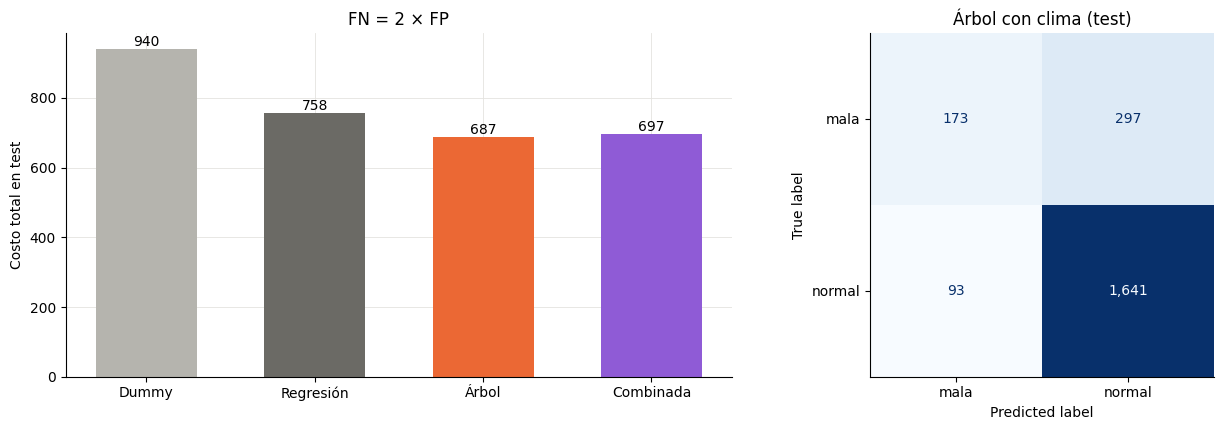

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.4, 1]})

costos = tabla_clf.set_index("modelo")["costo"]
colores = ["#b5b4ae", "#6b6a65", "#eb6834", "#8f5bd6"]
axes[0].bar(range(len(costos)), costos.to_numpy(), color=colores, width=0.6)
axes[0].set_xticks(range(len(costos)))
axes[0].set_xticklabels(["Dummy", "Regresión", "Árbol", "Combinada"])
axes[0].set_ylabel("Costo total en test")
axes[0].set_title("FN = 2 × FP")
for pos, valor in enumerate(costos.to_numpy()):
    axes[0].annotate(f"{valor:.0f}", (pos, valor), ha="center", va="bottom", fontsize=10)

fila = comparacion_clf.set_index("modelo").loc[res_clf["seleccionado"]]
matriz = np.array(
    [[int(fila["tp"]), int(fila["fn"])], [int(fila["fp"]), int(fila["tn"])]], dtype=int
)
ConfusionMatrixDisplay(matriz, display_labels=["mala", "normal"]).plot(
    ax=axes[1], colorbar=False, cmap="Blues", values_format=",d"
)
axes[1].set_title("Árbol con clima (test)")
axes[1].grid(False)
fig.tight_layout()
plt.show()

### 6.1 Acuerdo entre los dos sistemas

La tabla de acuerdo muestra qué pasa cuando se cruzan las dos alertas en test:

In [17]:
display(res_clf["acuerdo"].round(3))

,clasificador,regresion,n,malas_reales,precision
0,alerta,alerta,114,102,0.895
1,alerta,normal,152,71,0.467
2,normal,alerta,25,5,0.200
3,normal,normal,1913,292,0.153


Cuando los dos sistemas coinciden en alertar, 102 de 114 alertas son campañas malas reales: 89,5 % de precisión. Cuando alerta solo la regresión, la precisión cae al 20 %, casi la tasa base. La coincidencia, entonces, sirve como etiqueta de confianza; la alerta suelta de la regresión, no.

## 7. Integración: los modelos guardados

La aplicación no reentrena: carga los dos pipelines ya entrenados desde `modelos/`. Acá se verifica el contrato de entrada, es decir, que las columnas que espera cada modelo sean exactamente las que arma el formulario.

In [18]:
regresor = joblib.load(MODELOS_DIR / "regresor.joblib")
clasificador = joblib.load(MODELOS_DIR / "clasificador.joblib")
meta_reg = json.loads((MODELOS_DIR / "regresor_metadata.json").read_text(encoding="utf-8"))
meta_clf = json.loads((MODELOS_DIR / "clasificador_metadata.json").read_text(encoding="utf-8"))

print("Regresor:", meta_reg["modelo"], "|", meta_reg["variables"], "|", meta_reg["params"])
print(
    "Clasificador:",
    meta_clf["modelo"],
    "|",
    meta_clf["variables"],
    "|",
    meta_clf["params"],
    "| umbral",
    meta_clf["umbral_decision"],
)

entradas_clf = set(clasificador.feature_names_in_)
esperadas = {"cultivo", "superficie_sembrada", "prev5", "prev5_ceros", *CLIMA_COLS}
assert entradas_clf == esperadas, entradas_clf ^ esperadas
assert set(regresor.feature_names_in_) == esperadas
print("Contrato de entrada verificado:", len(esperadas), "columnas")

Regresor: KNeighborsRegressor | con_clima | {'n_neighbors': 300, 'weights': 'distance'}
Clasificador: DecisionTreeClassifier | con_clima | {'max_depth': 5, 'min_samples_leaf': 50, 'class_weight': None} | umbral 0.65
Contrato de entrada verificado: 13 columnas


### 7.1 Un caso concreto: soja 2022/23 en Pergamino

Se toma una fila real del test y se la pasa por el mismo código que usa la aplicación, para comprobar que el notebook y la web dan el mismo resultado.

In [19]:
caso = con_clima.query(
    "municipio_nombre == 'Pergamino' and cultivo == 'Soja total' and campania_inicio == 2022"
)
assert len(caso) == 1
fila = caso.iloc[0]

import app as app_web

valores = {col: fila[col] for col in ["cultivo", "superficie_sembrada", "prev5", "prev5_ceros", *CLIMA_COLS]}
resultado = app_web._predecir(valores)


def num(valor: float, decimales: int = 3) -> str:
    # Separador de miles con punto y coma decimal, como el resto del informe.
    texto = f"{valor:,.{decimales}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


tabla_caso = pd.DataFrame(
    [
        ("Rendimiento real (kg/ha)", num(fila["rendimiento"], 0)),
        ("Ratio real", num(fila["ratio"])),
        ("Rendimiento predicho (kg/ha)", num(resultado["rend_pred_kg"], 0)),
        ("Ratio predicho por el regresor", num(resultado["ratio_pred"])),
        ("¿Alerta del regresor?", "sí" if resultado["alerta_regresion"] else "no"),
        ("Probabilidad del clasificador", num(resultado["proba_clasificador"])),
        ("Umbral del clasificador", num(resultado["umbral_clasificador"], 2)),
        ("¿Alerta del clasificador?", "sí" if resultado["alerta_clasificador"] else "no"),
        ("Nivel que muestra la app", resultado["nivel"]),
    ],
    columns=["dato", "valor"],
)
display(tabla_caso)

,dato,valor
0,Rendimiento real (kg/ha),1.857
1,Ratio real,"0,524"
2,Rendimiento predicho (kg/ha),2.792
3,Ratio predicho por el regresor,"0,787"
4,¿Alerta del regresor?,sí
5,Probabilidad del clasificador,"1,000"
6,Umbral del clasificador,"0,65"
7,¿Alerta del clasificador?,sí
8,Nivel que muestra la app,alta


La campaña 2022/23 fue la de la sequía: el rendimiento real quedó muy por debajo del promedio de las cinco campañas anteriores. Los dos sistemas alertan y la aplicación muestra el nivel **alta**, que es el caso en el que la coincidencia tiene 89,5 % de precisión en test. El ejemplo sirve además para ver el orden de magnitud del error: el ratio predicho se queda corto, porque el modelo tiende a la media.

## 8. Resumen de la comparación integrada

La tabla junta los cuatro sistemas sobre el mismo test de 2.204 campañas, de las cuales 470 son malas:

In [20]:
resumen_final = pd.DataFrame(
    [
        {
            "sistema": etiqueta,
            "detecta": int(comparacion_clf.set_index("modelo").loc[nombre, "tp"]),
            "precisión": float(comparacion_clf.set_index("modelo").loc[nombre, "precision"]),
            "costo": float(comparacion_clf.set_index("modelo").loc[nombre, "costo"]),
            "comentario": comentario,
        }
        for etiqueta, nombre, comentario in [
            ("Dummy (nunca alerta)", MODEL_LABELS["dummy"], "piso trivial"),
            (
                "Regresión + umbral (0,85)",
                MODEL_LABELS["regresion"],
                "buena precisión, detecta solo la sequía",
            ),
            (
                "Árbol con clima (umbral 0,65)",
                res_clf["seleccionado"],
                "elegido por costo en validación",
            ),
            (
                "Alerta combinada (OR)",
                MODEL_LABELS["combinada"],
                "más falsas alarmas, no mejora el costo",
            ),
        ]
    ]
)
resumen_final["recall"] = resumen_final["detecta"] / int(
    con_clima.query("split == 'test'")["mala85"].sum()
)
display(resumen_final.round(3))

,sistema,detecta,precisión,costo,comentario,recall
0,Dummy (nunca alerta),0,0.000,940.0,piso trivial,0.000
1,"Regresión + umbral (0,85)",107,0.770,758.0,"buena precisión, detecta solo la sequía",0.228
2,"Árbol con clima (umbral 0,65)",173,0.650,687.0,elegido por costo en validación,0.368
3,Alerta combinada (OR),178,0.612,697.0,"más falsas alarmas, no mejora el costo",0.379


En orden de costo, el árbol gana, la combinada queda apenas arriba y la regresión tercera. Ninguna alternativa baja del costo del árbol: el techo está en que las campañas malas por poco margen y las causadas por granizo, plagas o excesos de agua puntuales no se ven en las variables de la ventana climática.

## 9. Limitaciones

- **Falsos negativos.** El árbol detecta 173 de 470 campañas malas. La mitad de las que se escapan tienen un ratio entre 0,75 y 0,85: son caídas moderadas, donde el costo de equivocarse es menor, pero también son las más difíciles de separar.
- **Sesgo de nivel.** El ratio medio baja de 1,08 en train a 0,96 en test. El modelo sobreestima las campañas 2019/20 a 2021/22 y solo la sequía lo devuelve a rango.
- **Cobertura del clima.** Las variables resumen la ventana de cada cultivo. No capturan eventos puntuales como granizo, heladas tardías localizadas o anegamientos, que explican buena parte de los falsos negativos.
- **Probabilidades sin calibrar.** El umbral de 0,65 no es el teórico de 0,33. Calibrar con validación es la mejora pendiente más directa.
- **Un solo período de test.** Seis campañas alcanzan para comparar sistemas, no para estimar con precisión el desempeño esperado en otra década.

## 10. Cómo regenerar todo

Cada etapa también se puede ejecutar por consola, en este orden:

```bash
python -m src.descargar_datos
python -m src.preparar_datos
python -m src.clima
python -m src.baselines
python -m src.regresion
python -m src.clasificacion
python -m pytest -q
```

Los artefactos quedan en `datos/procesado/` (tablas), `modelos/` (pipelines y metadata) e `informe/figuras/` (figuras). La aplicación se levanta con `python app.py` y está publicada en https://tp-integrador-rendimiento-cultivos.vercel.app.

In [21]:
artefactos = [
    (p.relative_to(ROOT).as_posix(), round(p.stat().st_size / 1024, 1))
    for p in sorted(MODELOS_DIR.iterdir())
    if p.suffix in {".joblib", ".json"}
]
display(pd.DataFrame(artefactos, columns=["artefacto", "KB"]))
print("Tablas en datos/procesado:", len(list(DATASET_MODELADO.parent.glob("*.csv"))))
print("Figuras en informe/figuras:", len(list(FIGURAS_DIR.glob("*.png"))))
print("Verificación completa.")

,artefacto,KB
0,modelos/clasificador.joblib,9.8
1,modelos/clasificador_metadata.json,1.4
2,modelos/regresor.joblib,1728.1
3,modelos/regresor_metadata.json,1.2


Tablas en datos/procesado: 25
Figuras en informe/figuras: 17
Verificación completa.
